In [1]:
import json
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tifffile
from sklearn.decomposition import FastICA, PCA

NOTEBOOK_DIR = Path.cwd().resolve()
if NOTEBOOK_DIR.name != "notebooks" and (NOTEBOOK_DIR / "notebooks").exists():
    NOTEBOOK_DIR = NOTEBOOK_DIR / "notebooks"
PROJECT_ROOT = NOTEBOOK_DIR.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from utils.movie_utils import get_mean_images, get_movie_parameters
from utils.paths_utils import resolve_sta_paths
from utils.spikes_utils import _suite2p_trace_dff
from utils.suite2p_utils import add_neuron_outlines, suite2p_roi_mask
from utils.sta_trace_utils import *

### Choose a single experiment

In [2]:
SINGLE_EXPERIMENT = "Hyp8__R__12-08-2026_ans__FOV1__z-120__x2"
DATA_ROOT = Path(r"Z:\Adam-Lab-Shared\Data\Miki_Meerson\Imaging\HYP-JEDI")
RUN_ROOT = PROJECT_ROOT / "runtime" / "outputs"

def experiment_path(canonical_id):
    cage, side, date_behavior, fov, z, x = canonical_id.split("__")
    return DATA_ROOT / cage / side / date_behavior.replace("_", "-", 1) / fov / f"{z}-{x}"

source_path = experiment_path(SINGLE_EXPERIMENT)
sta_run = sorted(RUN_ROOT.glob(f"{SINGLE_EXPERIMENT}__cell_all__sta__run_*"), key=lambda p: p.stat().st_mtime)[-1]
paths = resolve_sta_paths(source_path, sta_run)
params = json.loads((sta_run / "sta_maps_job_params.effective.json").read_text())
spike_run = Path(params["spike_run"])

ops = np.load(paths.suite2p_path / "ops.npy", allow_pickle=True).item()
iscell = np.load(paths.suite2p_path / "iscell.npy", allow_pickle=True)[:, 0].astype(bool)
stat_cells = np.load(paths.suite2p_path / "stat.npy", allow_pickle=True)[iscell]
F_cells = np.load(paths.suite2p_path / "F.npy", mmap_mode="r")[iscell]
all_cell_ids = np.arange(len(stat_cells), dtype=int)
fps = int(get_movie_parameters(f"{paths.home_dir.as_posix()}/", is_dir=True)["fps"])

summary = pd.read_csv(paths.sta_dir / "sta_maps_batch_summary.csv")
anatomy_cell_ids = np.sort(summary.loc[(summary.spike_group == "anatomy") & (summary.n_significant_clusters > 0), "cell_id"].astype(int).unique())
spike_peaks = {}
for cell_id in all_cell_ids:
    path = spike_run / f"cell_{cell_id}" / "simple_complex_spike_labels.npz"
    if path.exists():
        with np.load(path, allow_pickle=True) as d:
            spike_peaks[int(cell_id)] = np.asarray(d["peaks_all"], dtype=int)

display(pd.DataFrame([{
    "canonical_id": SINGLE_EXPERIMENT,
    "source_path": str(source_path),
    "sta_run": sta_run.name,
    "n_suite2p_cells": len(all_cell_ids),
    "n_cells_with_sig_anatomy": len(anatomy_cell_ids),
    "fps": fps,
}]))

,canonical_id,source_path,sta_run,n_suite2p_cells,n_cells_with_sig_anatomy,fps
0,Hyp8__R__12-08-2026_ans__FOV1__z-120__x2,Z:\Adam-Lab-Shared\Data\Miki_Meerson\Imaging\H...,Hyp8__R__12-08-2026_ans__FOV1__z-120__x2__cell...,272,16,29


### Neurons Display

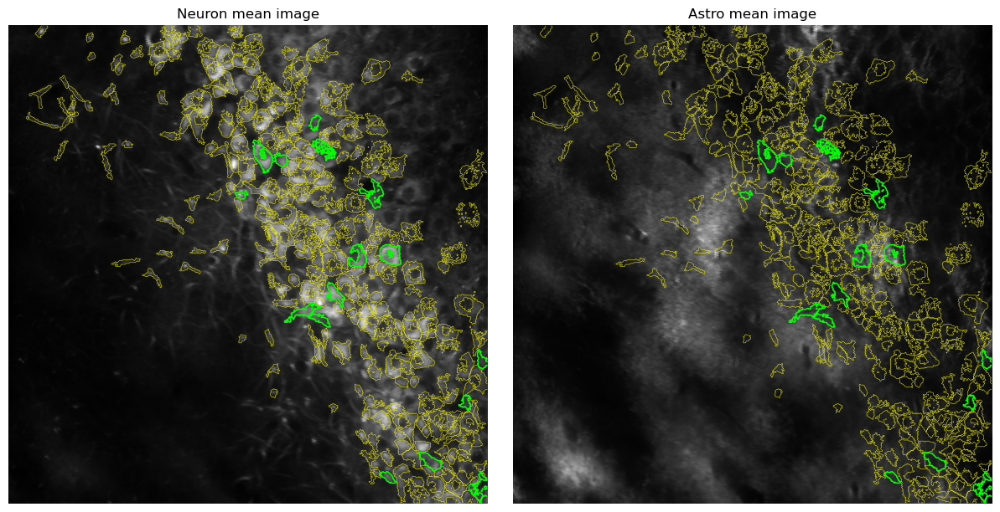

In [3]:
mean_astro, mean_neuron = get_mean_images(paths.mc_dir, spatial_bin=1)
image_shape = tuple(mean_astro.shape)

fig, axes = plt.subplots(1, 2, figsize=(12, 6), constrained_layout=True)
for ax, image, title in zip(axes, [mean_neuron, mean_astro], ["Neuron mean image", "Astro mean image"]):
    ax.imshow(image, cmap="gray")
    add_neuron_outlines(ax, all_cell_ids, stat_cells, image_shape, color="yellow", linewidth=0.35)
    add_neuron_outlines(ax, anatomy_cell_ids, stat_cells, image_shape, color="lime", linewidth=1.1)
    ax.set_title(title)
    ax.axis("off")
plt.show()

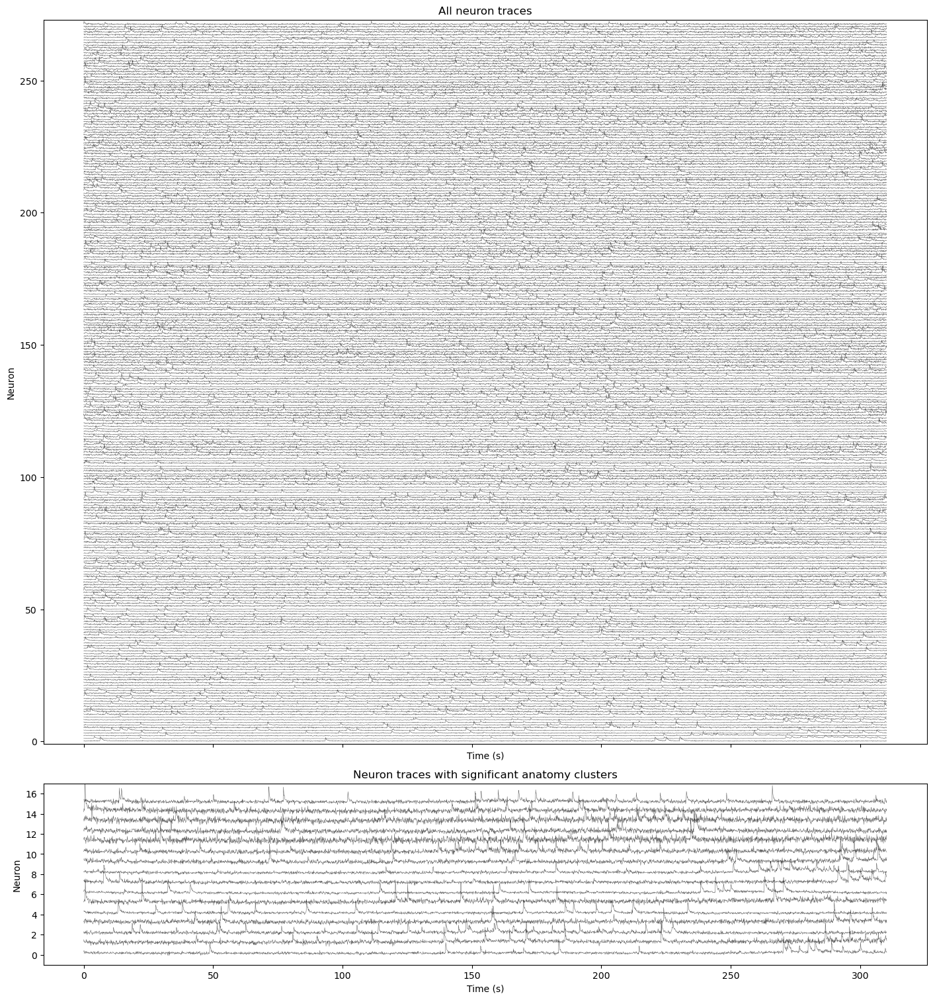

In [4]:
def plot_traces(ax, cell_ids, title):
    traces = np.asarray(F_cells[cell_ids], dtype=float)
    lo = np.percentile(traces, 1, axis=1, keepdims=True)
    hi = np.percentile(traces, 99, axis=1, keepdims=True)
    traces = (traces - lo) / (hi - lo + 1e-12)
    step = max(1, traces.shape[1] // 3000)
    t = np.arange(traces.shape[1])[::step] / fps
    for i, trace in enumerate(traces[:, ::step]):
        ax.plot(t, trace + i, color="black", lw=0.35, alpha=0.65)
    ax.set_title(title)
    ax.set_ylabel("Neuron")
    ax.set_xlabel("Time (s)")
    ax.set_ylim(-1, len(cell_ids) + 1)

fig, axes = plt.subplots(2, 1, figsize=(14, 15), height_ratios=[4,1], sharex=True, constrained_layout=True)
plot_traces(axes[0], all_cell_ids, "All neuron traces")
plot_traces(axes[1], anatomy_cell_ids, "Neuron traces with significant anatomy clusters")
plt.show()

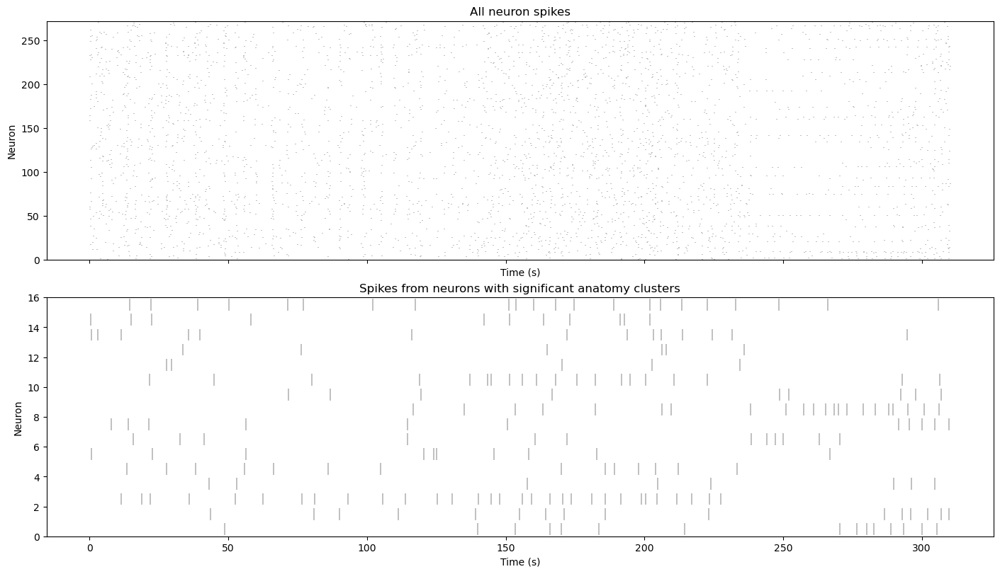

In [5]:
def plot_raster(ax, cell_ids, title):
    for row, cell_id in enumerate(cell_ids):
        peaks = spike_peaks.get(int(cell_id), np.empty(0, dtype=int))
        ax.vlines(peaks / fps, row + 0.1, row + 0.9, color="black", lw=0.35)
    ax.set_title(title)
    ax.set_ylabel("Neuron")
    ax.set_xlabel("Time (s)")
    ax.set_ylim(0, len(cell_ids))

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True, constrained_layout=True)
plot_raster(axes[0], all_cell_ids, "All neuron spikes")
plot_raster(axes[1], anatomy_cell_ids, "Spikes from neurons with significant anatomy clusters")
plt.show()

### Clusters Traces Display 

Saved raw ROI trace cache: \\ems\adam-lab\Adam-Lab-Shared\Code\Miki\astro-analysis-pipeline\notebooks\.cache\Hyp8__R__12-08-2026_ans__FOV1__z-120__x2_Hyp8__R__12-08-2026_ans__FOV1__z-120__x2__cell_all__sta__run_75_anatomy_cluster_raw_roi_traces_full.npz


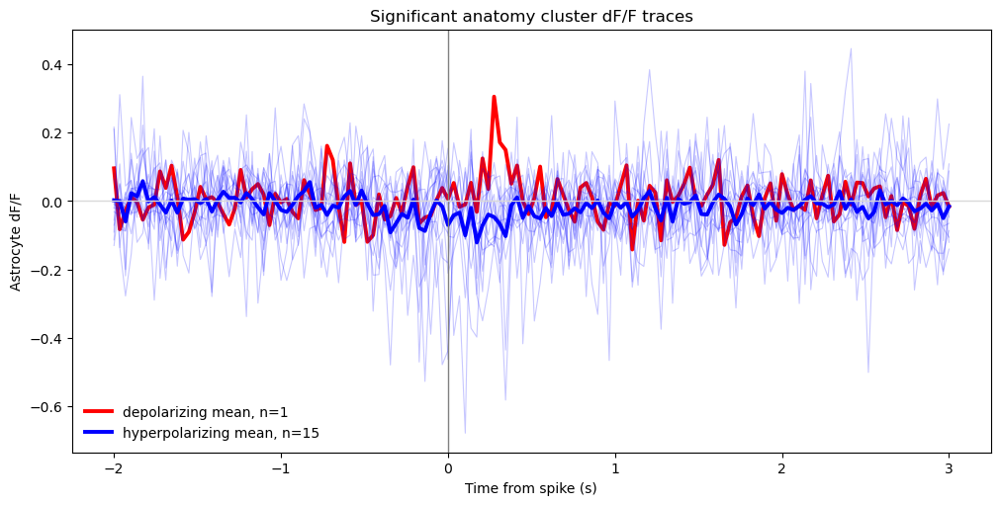

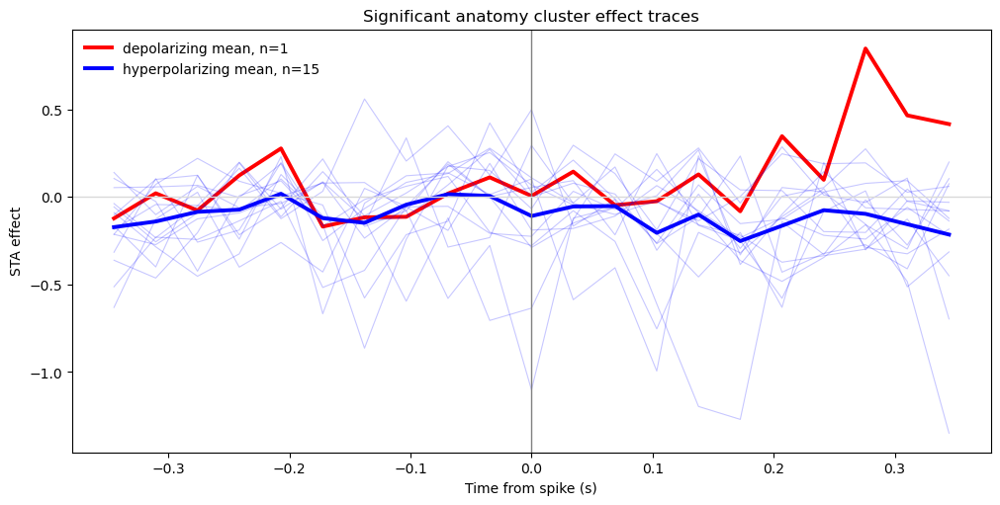

In [6]:
import hashlib
import importlib
import utils.sta_trace_utils as sta_trace_utils
sta_trace_utils = importlib.reload(sta_trace_utils)

cluster_colors = {"positive": "red", "negative": "blue"}
cluster_labels = {"positive": "depolarizing", "negative": "hyperpolarizing"}
astro_movie = tifffile.memmap(paths.astro_movie_path)

roi_cache_dir = NOTEBOOK_DIR / ".cache"
roi_cache_dir.mkdir(exist_ok=True)
roi_cache_path = roi_cache_dir / f"{SINGLE_EXPERIMENT}_{sta_run.name}_anatomy_cluster_raw_roi_traces_full.npz"
movie_mtime_ns = int(Path(paths.astro_movie_path).stat().st_mtime_ns)
roi_trace_cache = {}
if roi_cache_path.exists():
    with np.load(roi_cache_path, allow_pickle=True) as cache:
        cached_mtime = int(np.asarray(cache.get("movie_mtime_ns", -1)).item()) if "movie_mtime_ns" in cache else -1
        cached_frames = int(np.asarray(cache.get("n_frames", -1)).item()) if "n_frames" in cache else -1
        if cached_mtime == movie_mtime_ns and cached_frames == int(astro_movie.shape[0]):
            roi_trace_cache = {k.replace("trace__", "", 1): np.asarray(cache[k], dtype=np.float32) for k in cache.files if k.startswith("trace__")}
cache_changed = False

def mask_cache_key(cell_id, row):
    mask = np.asarray(row["mask_full"], dtype=bool)
    digest = hashlib.sha1(np.packbits(mask).tobytes()).hexdigest()[:16]
    return f"cell_{int(cell_id)}_cluster_{int(row.get('component_id', 0))}_{row.get('sign', 'unknown')}_{digest}"

def plot_cluster_trace_groups(rows, trace_key, time_key, ylabel, title):
    fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
    for sign in ["positive", "negative"]:
        sign_rows = [r for r in rows if r["sign"] == sign and trace_key in r and np.asarray(r[trace_key]).size]
        if not sign_rows:
            continue
        min_len = min(len(r[trace_key]) for r in sign_rows)
        arr = np.vstack([np.asarray(r[trace_key], dtype=float)[:min_len] for r in sign_rows])
        t_rel = np.asarray(sign_rows[0][time_key], dtype=float)[:min_len]
        t = t_rel / fps
        color = cluster_colors[sign]
        for y in arr:
            ax.plot(t, y, color=color, lw=0.8, alpha=0.22)
        ax.plot(t, np.nanmean(arr, axis=0), color=color, lw=2.8, label=f"{cluster_labels[sign]} mean, n={arr.shape[0]}")
    ax.axvline(0, color="0.5", lw=1)
    ax.axhline(0, color="0.85", lw=1)
    ax.set_title(title)
    ax.set_xlabel("Time from spike (s)")
    ax.set_ylabel(ylabel)
    ax.legend(frameon=False)
    plt.show()

cluster_trace_rows = []
for cell_id in anatomy_cell_ids:
    npz_path = paths.sta_dir / f"cell_{int(cell_id)}" / "astro_sta_cluster_permutation_anatomy.npz"
    if not npz_path.exists():
        continue
    for spec in sta_trace_utils.significant_cluster_specs_from_npz(npz_path, cluster_colors):
        mask_full = sta_trace_utils.crop_mask_to_fullres(spec["mask_crop"], spec["crop"], spec["spatial_bin"], image_shape)
        row = {**spec, "cell_id": int(cell_id), "mask_full": mask_full}
        key = mask_cache_key(cell_id, row)
        if key not in roi_trace_cache:
            roi_trace_cache[key] = sta_trace_utils.cluster_raw_trace_from_movie(astro_movie, mask_full)
            cache_changed = True
        trace = sta_trace_utils.spike_triggered_dff_trace(roi_trace_cache[key], spec["peaks"], spec["pre"], spec["post"])
        t_rel = np.arange(len(trace), dtype=int) - int(spec["pre"])
        cluster_trace_rows.append({**row, "raw_roi_trace": roi_trace_cache[key], "trace": trace, "t_rel": t_rel})

if cache_changed:
    np.savez_compressed(
        roi_cache_path,
        movie_mtime_ns=np.asarray(movie_mtime_ns, dtype=np.int64),
        n_frames=np.asarray(int(astro_movie.shape[0]), dtype=np.int64),
        **{f"trace__{k}": np.asarray(v, dtype=np.float32) for k, v in roi_trace_cache.items()},
    )
    print(f"Saved raw ROI trace cache: {roi_cache_path}")
else:
    print(f"Used raw ROI trace cache: {roi_cache_path}")

if cluster_trace_rows:
    plot_cluster_trace_groups(
        cluster_trace_rows,
        trace_key="trace",
        time_key="t_rel",
        ylabel="Astrocyte dF/F",
        title="Significant anatomy cluster dF/F traces",
    )
    plot_cluster_trace_groups(
        cluster_trace_rows,
        trace_key="effect_trace",
        time_key="effect_t_rel",
        ylabel="STA effect",
        title="Significant anatomy cluster effect traces",
    )
else:
    print("No significant anatomical cluster traces found.")

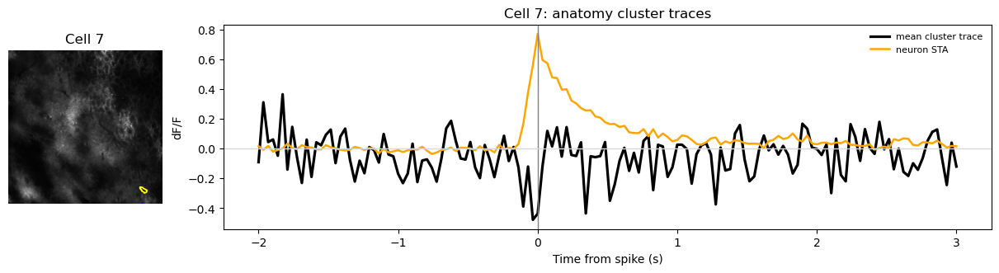

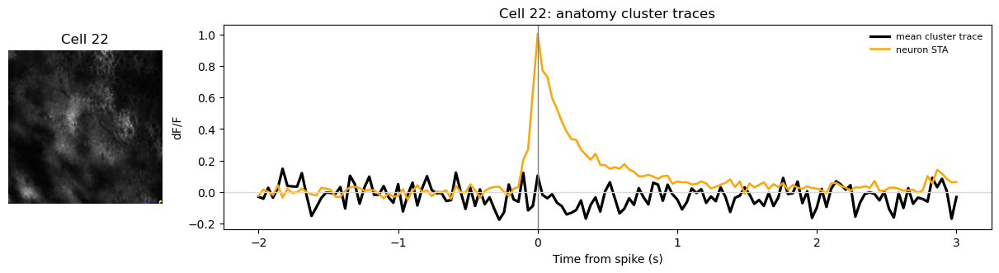

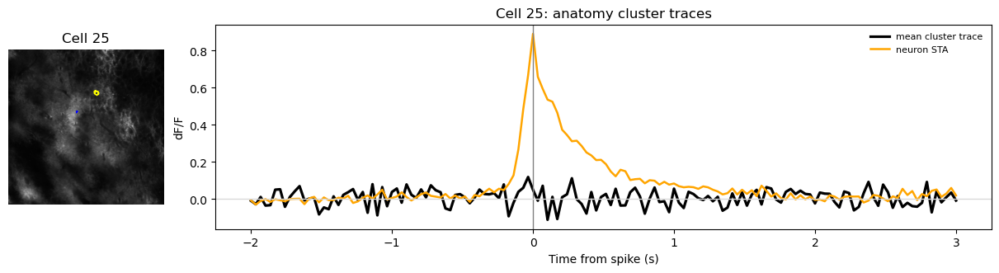

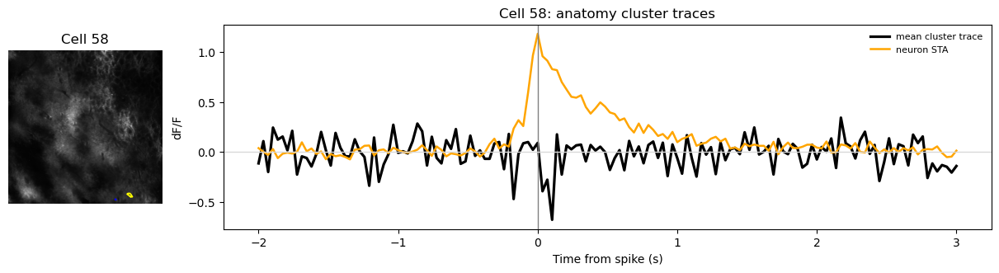

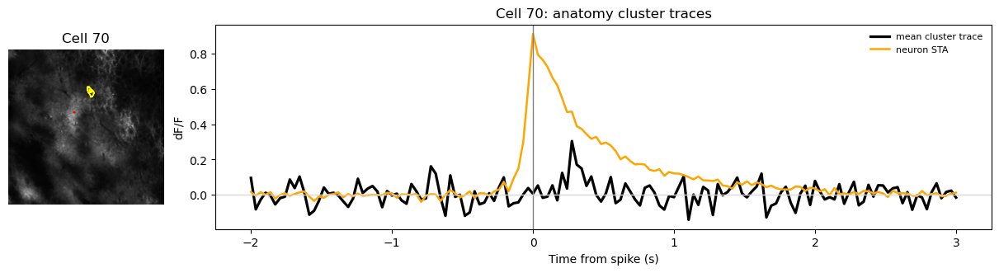

...

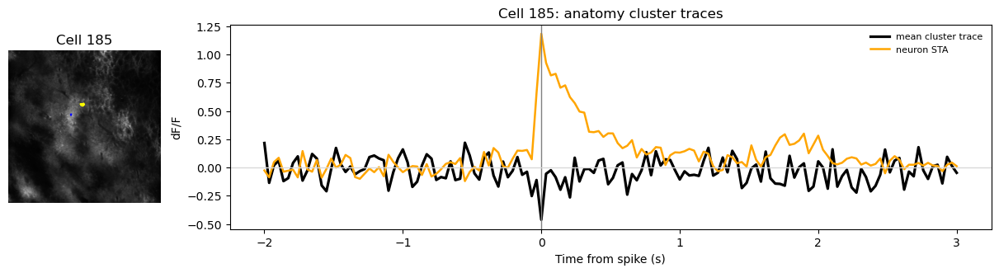

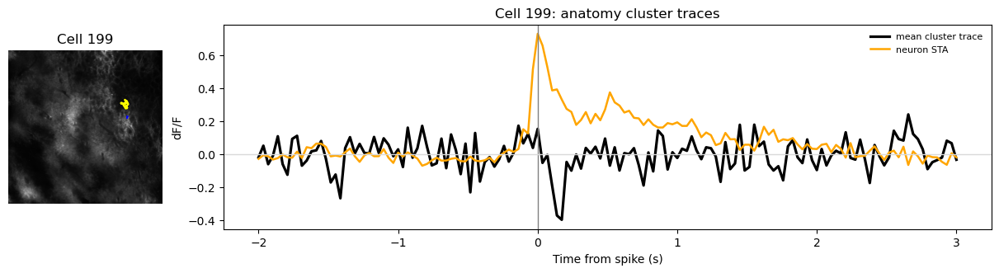

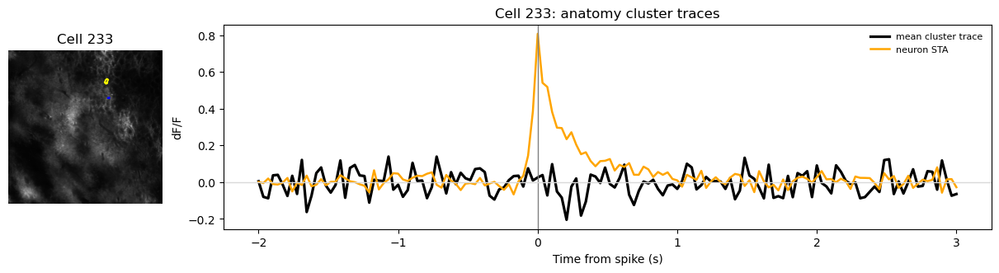

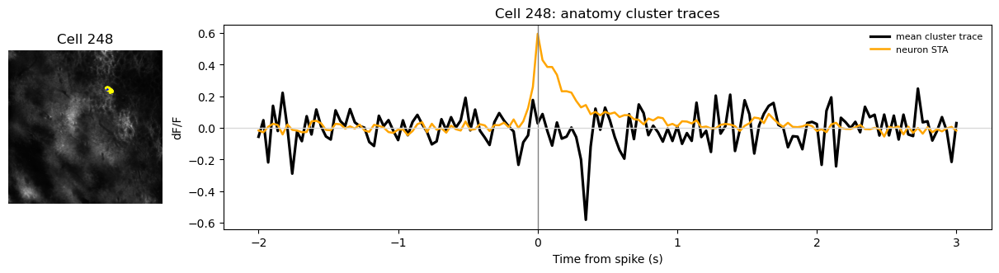

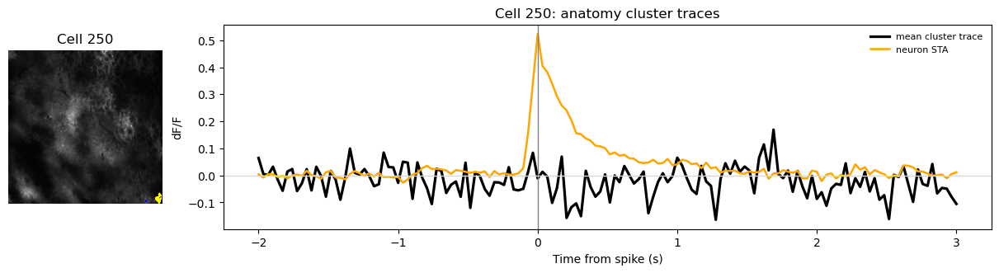

In [7]:
for cell_id in anatomy_cell_ids:
    rows = [r for r in cluster_trace_rows if r["cell_id"] == int(cell_id)]
    if not rows:
        continue
    pre, post = int(rows[0]["pre"]), int(rows[0]["post"])
    t = (np.arange(pre + post + 1) - pre) / fps
    neuron_sta = spike_triggered_dff_trace(F_cells[int(cell_id)], rows[0]["peaks"], pre, post)

    fig, (ax_img, ax_trace) = plt.subplots(
        1, 2, figsize=(12, 3.2), width_ratios=[1, 5], constrained_layout=True
    )
    ax_img.imshow(mean_astro, cmap="gray")
    ax_img.contour(suite2p_roi_mask(cell_id, stat_cells, image_shape, exclude_overlap=True).astype(float), levels=[0.5], colors="yellow", linewidths=1.2)
    for r in rows:
        ax_img.contour(r["mask_full"].astype(float), levels=[0.5], colors=cluster_colors.get(r["sign"], "white"), linewidths=1.0)
    ax_img.set_title(f"Cell {cell_id}")
    ax_img.axis("off")

    for r in rows:
        ax_trace.plot(t, r["trace"], color=cluster_colors.get(r["sign"], "0.5"), lw=0.9, alpha=0.35)
    arr = np.vstack([r["trace"] for r in rows])
    ax_trace.plot(t, np.nanmean(arr, axis=0), color="black", lw=2.3, label="mean cluster trace")
    ax_trace.plot(t, neuron_sta, color="orange", lw=1.8, label="neuron STA")
    ax_trace.axvline(0, color="0.5", lw=1)
    ax_trace.axhline(0, color="0.85", lw=1)
    ax_trace.set_title(f"Cell {cell_id}: anatomy cluster traces")
    ax_trace.set_xlabel("Time from spike (s)")
    ax_trace.set_ylabel("dF/F")
    ax_trace.legend(frameon=False, fontsize=8)
    plt.show()

### Raw Traces Display

In [14]:
%matplotlib widget

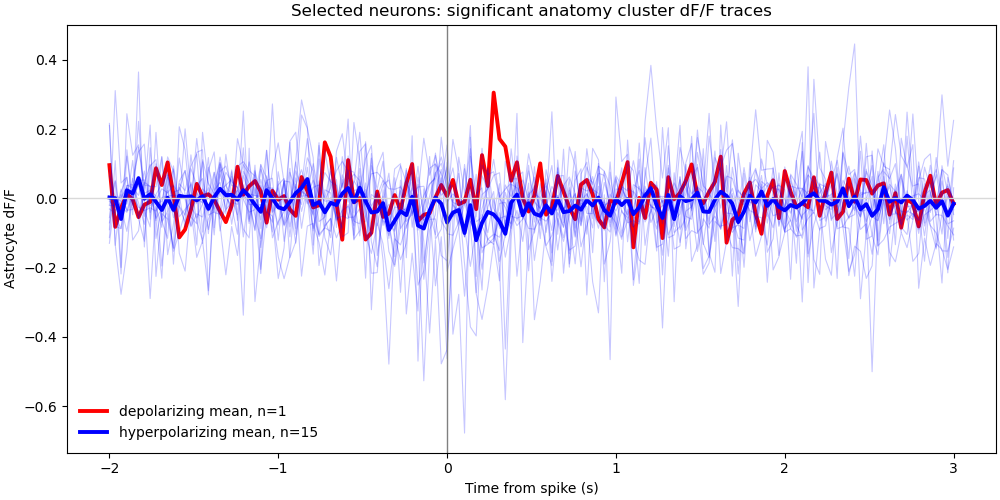

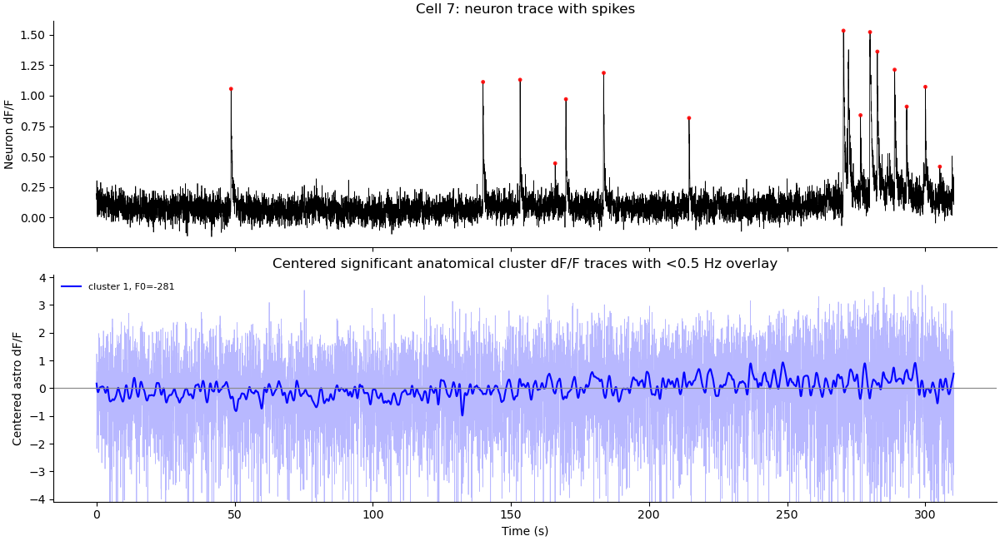

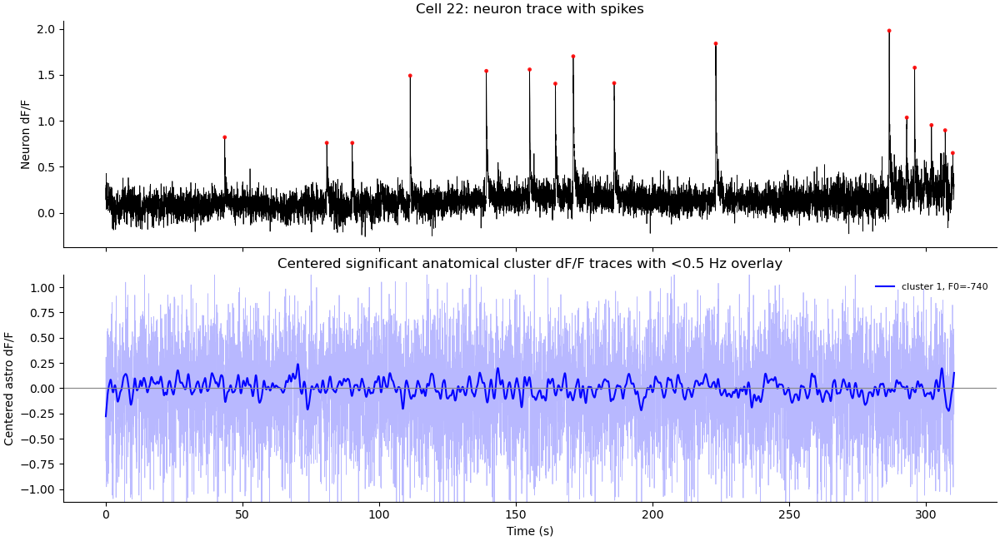

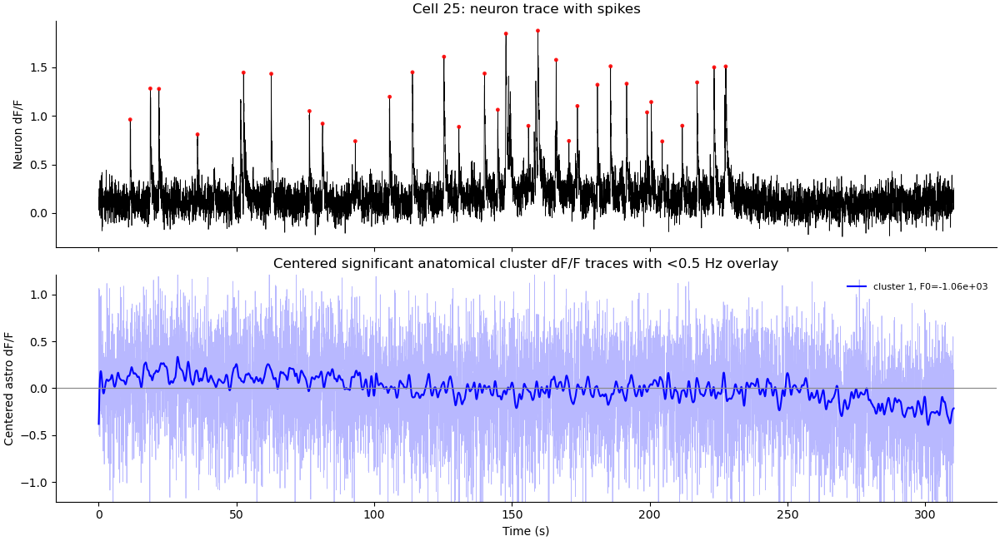

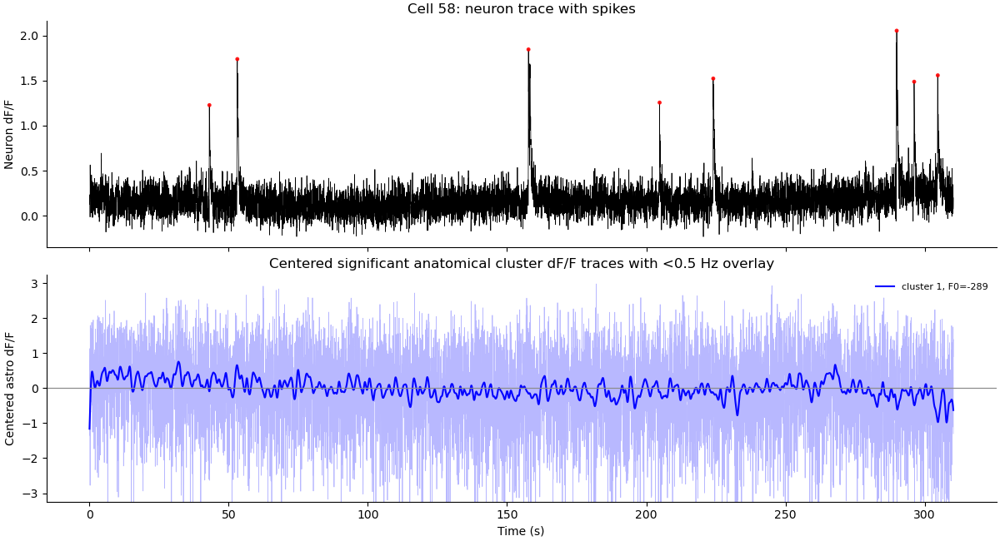

...

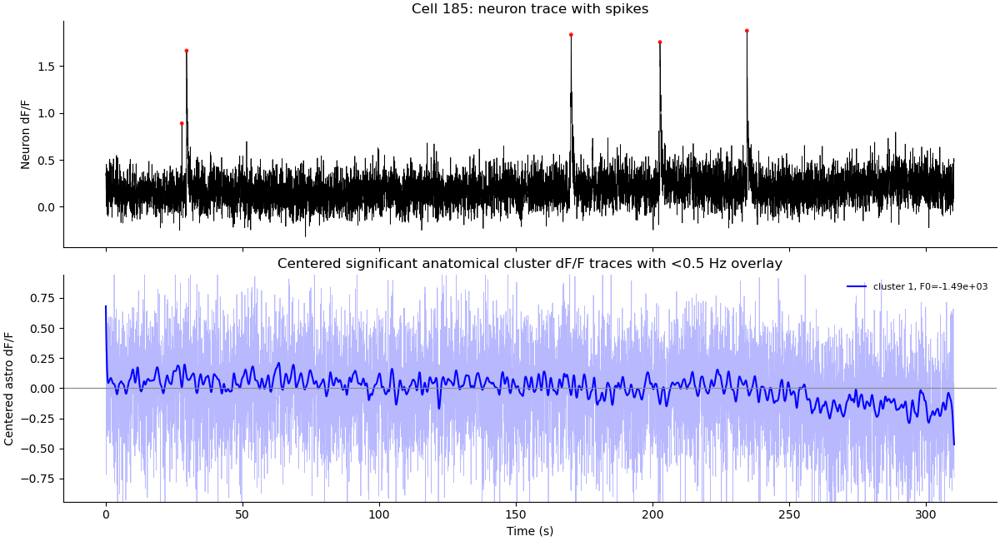

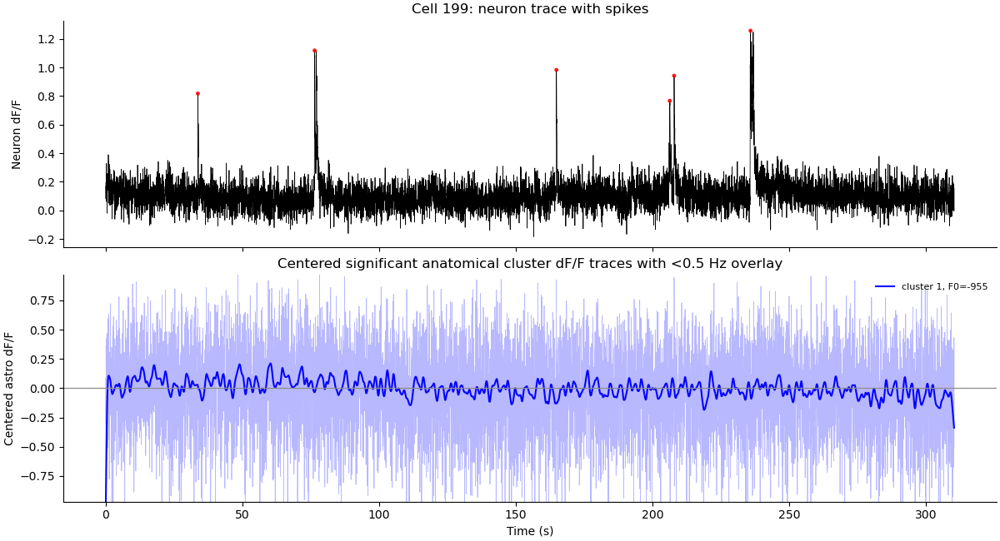

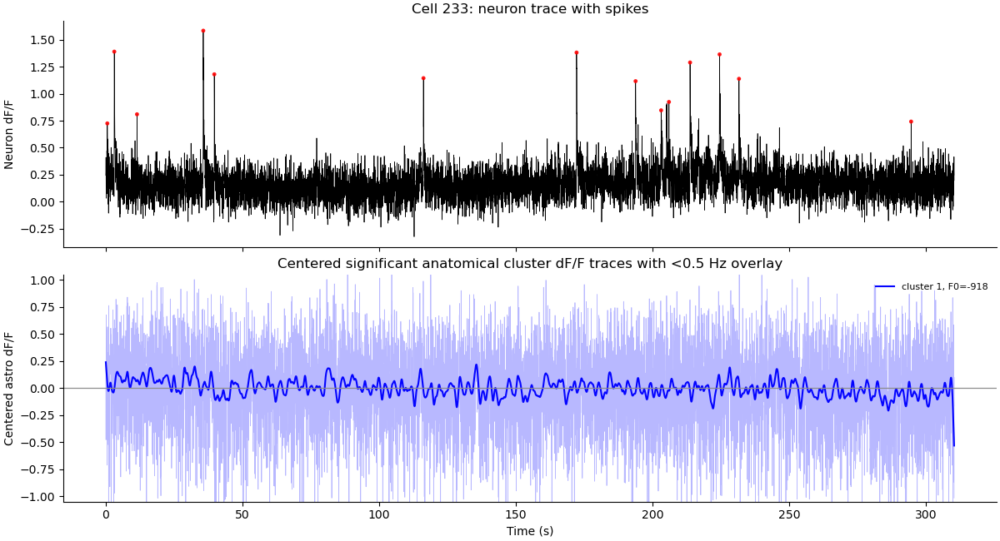

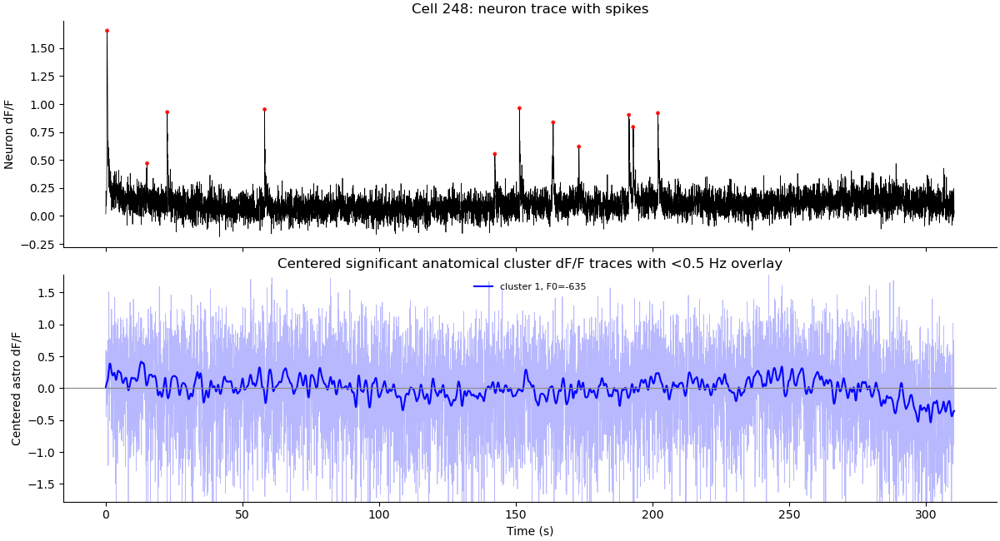

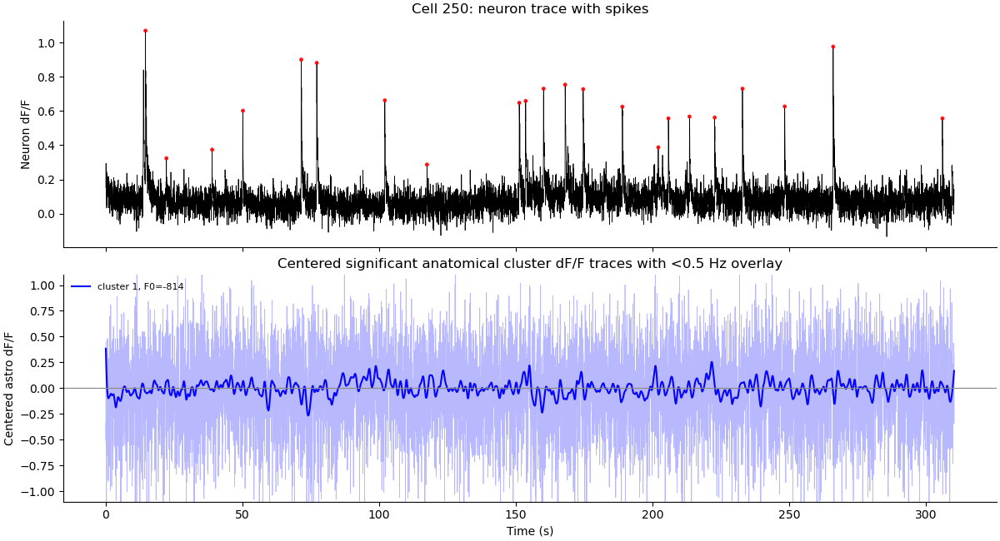

Used raw cluster trace cache: \\ems\adam-lab\Adam-Lab-Shared\Code\Miki\astro-analysis-pipeline\notebooks\.cache\Hyp8__R__12-08-2026_ans__FOV1__z-120__x2_Hyp8__R__12-08-2026_ans__FOV1__z-120__x2__cell_all__sta__run_75_anatomy_raw_cluster_traces_display.npz


In [18]:
selected_neuron_ids = [7, 22, 25, 58, 70, 92, 95, 114, 162, 171, 183, 185, 199, 233, 248, 250]
cluster_colors = globals().get("cluster_colors", {"positive": "red", "negative": "blue"})
astro_movie = globals().get("astro_movie", tifffile.memmap(paths.astro_movie_path))

trace_len = min(F_cells.shape[1], astro_movie.shape[0])
step = max(1, trace_len // 6000)
display_frames = np.arange(0, trace_len, step, dtype=int)
display_time_s = display_frames / fps
display_sample_rate_hz = fps / step
LOWPASS_CUTOFF_HZ = 0.5

raw_cache_dir = NOTEBOOK_DIR / ".cache"
raw_cache_dir.mkdir(exist_ok=True)
raw_cache_path = raw_cache_dir / f"{SINGLE_EXPERIMENT}_{sta_run.name}_anatomy_raw_cluster_traces_display.npz"
movie_mtime_ns = int(Path(paths.astro_movie_path).stat().st_mtime_ns)
raw_trace_cache = {}
if raw_cache_path.exists():
    with np.load(raw_cache_path, allow_pickle=True) as cache:
        cached_mtime = int(np.asarray(cache.get("movie_mtime_ns", -1)).item()) if "movie_mtime_ns" in cache else -1
        cached_frames = np.asarray(cache.get("display_frames", []), dtype=int)
        if cached_mtime == movie_mtime_ns and np.array_equal(cached_frames, display_frames):
            raw_trace_cache = {k.replace("trace__", "", 1): np.asarray(cache[k], dtype=np.float32) for k in cache.files if k.startswith("trace__")}

cache_changed = False

def anatomy_rows_for_cell(cell_id):
    rows = [r for r in globals().get("cluster_trace_rows", []) if int(r["cell_id"]) == int(cell_id)]
    if rows:
        return rows
    npz_path = paths.sta_dir / f"cell_{int(cell_id)}" / "astro_sta_cluster_permutation_anatomy.npz"
    if not npz_path.exists():
        return []
    built = []
    for spec in significant_cluster_specs_from_npz(npz_path, cluster_colors):
        mask_full = crop_mask_to_fullres(spec["mask_crop"], spec["crop"], spec["spatial_bin"], image_shape)
        built.append({**spec, "cell_id": int(cell_id), "mask_full": mask_full})
    return built

def raw_trace_key(row):
    mask = np.asarray(row["mask_full"], dtype=bool)
    yy, xx = np.where(mask)
    if yy.size:
        bounds = (int(yy.min()), int(yy.max()), int(xx.min()), int(xx.max()))
    else:
        bounds = (-1, -1, -1, -1)
    return f"cell_{int(row['cell_id'])}_cluster_{int(row.get('component_id', 0))}_{row.get('sign', 'unknown')}_px_{int(mask.sum())}_b_{'_'.join(map(str, bounds))}"

def ensure_dff_trace(row):
    if "trace" not in row or "t_rel" not in row:
        row["trace"] = cluster_dff_trace_from_movie(astro_movie, row["mask_full"], row["peaks"], row["pre"], row["post"])
        row["t_rel"] = np.arange(len(row["trace"]), dtype=int) - int(row["pre"])
    return row

selected_cluster_rows = []
for cell_id in selected_neuron_ids:
    for row in anatomy_rows_for_cell(int(cell_id)):
        selected_cluster_rows.append(ensure_dff_trace(row))

if selected_cluster_rows:
    fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
    for sign, label in [("positive", "depolarizing"), ("negative", "hyperpolarizing")]:
        rows = [r for r in selected_cluster_rows if r.get("sign") == sign and np.asarray(r.get("trace", [])).size]
        if not rows:
            continue
        min_len = min(len(r["trace"]) for r in rows)
        arr = np.vstack([np.asarray(r["trace"], dtype=float)[:min_len] for r in rows])
        t_rel = np.asarray(rows[0]["t_rel"], dtype=float)[:min_len]
        t = t_rel / fps
        color = cluster_colors.get(sign, "0.4")
        for y in arr:
            ax.plot(t, y, color=color, lw=0.8, alpha=0.22)
        ax.plot(t, np.nanmean(arr, axis=0), color=color, lw=2.8, label=f"{label} mean, n={arr.shape[0]}")
    ax.axvline(0, color="0.5", lw=1)
    ax.axhline(0, color="0.85", lw=1)
    ax.set_title("Selected neurons: significant anatomy cluster dF/F traces")
    ax.set_xlabel("Time from spike (s)")
    ax.set_ylabel("Astrocyte dF/F")
    ax.legend(frameon=False)
    plt.show()
else:
    print("No significant anatomical cluster dF/F traces found for selected_neuron_ids.")

for cell_id in selected_neuron_ids:
    cell_id = int(cell_id)
    rows = anatomy_rows_for_cell(cell_id)
    if not rows:
        print(f"Cell {cell_id}: no significant anatomical clusters")
        continue

    neuron_trace = _suite2p_trace_dff(cell_id, F_raw=F_cells)[:trace_len]
    peaks = spike_peaks.get(cell_id, np.empty(0, dtype=int))
    peaks = peaks[(peaks >= 0) & (peaks < trace_len)]

    fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True, constrained_layout=True)
    ax_n, ax_a = axes

    ax_n.plot(display_time_s, neuron_trace[display_frames], color="black", lw=0.55)
    if peaks.size:
        ax_n.scatter(peaks / fps, neuron_trace[peaks], s=12, color="red", edgecolors="none", alpha=0.9, zorder=4)
    ax_n.set_title(f"Cell {cell_id}: neuron trace with spikes")
    ax_n.set_ylabel("Neuron dF/F")
    ax_n.spines[["top", "right"]].set_visible(False)

    y_values = []
    for i, r in enumerate(rows, start=1):
        key = raw_trace_key(r)
        if key not in raw_trace_cache:
            raw_trace_cache[key] = cluster_raw_trace_from_movie(astro_movie, r["mask_full"], frame_indices=display_frames)
            cache_changed = True
        raw = np.asarray(raw_trace_cache[key], dtype=float)
        r["raw_trace"] = raw
        y, f0 = dff_from_lowest_abs(raw, fraction=0.08)
        center = float(np.nanmedian(y)) if np.isfinite(y).any() else 0.0
        y = y - center
        low = lowpass_centered(y, display_sample_rate_hz, cutoff_hz=LOWPASS_CUTOFF_HZ)
        color = cluster_colors.get(r["sign"], "0.4")
        label = f"cluster {i}, F0={f0:.3g}"
        ax_a.plot(display_time_s, y, color=color, lw=0.55, alpha=0.28)
        ax_a.plot(display_time_s, low, color=color, lw=1.5, alpha=0.98, label=label)
        y_values.extend([y[np.isfinite(y)], low[np.isfinite(low)]])

    ax_a.axhline(0, color="0.55", lw=0.9)
    if y_values:
        vals = np.concatenate([v for v in y_values if v.size])
        lim = max(float(np.nanpercentile(np.abs(vals), 99)), 0.02) * 1.15
        ax_a.set_ylim(-lim, lim)
    ax_a.set_title("Centered significant anatomical cluster dF/F traces with <0.5 Hz overlay")
    ax_a.set_xlabel("Time (s)")
    ax_a.set_ylabel("Centered astro dF/F")
    ax_a.legend(frameon=False, fontsize=8, loc="best")
    ax_a.spines[["top", "right"]].set_visible(False)
    plt.show()

if cache_changed:
    np.savez_compressed(
        raw_cache_path,
        movie_mtime_ns=np.asarray(movie_mtime_ns, dtype=np.int64),
        display_frames=display_frames,
        **{f"trace__{k}": np.asarray(v, dtype=np.float32) for k, v in raw_trace_cache.items()},
    )
    print(f"Saved raw cluster trace cache: {raw_cache_path}")
else:
    print(f"Used raw cluster trace cache: {raw_cache_path}")

### Padded Raw Traces


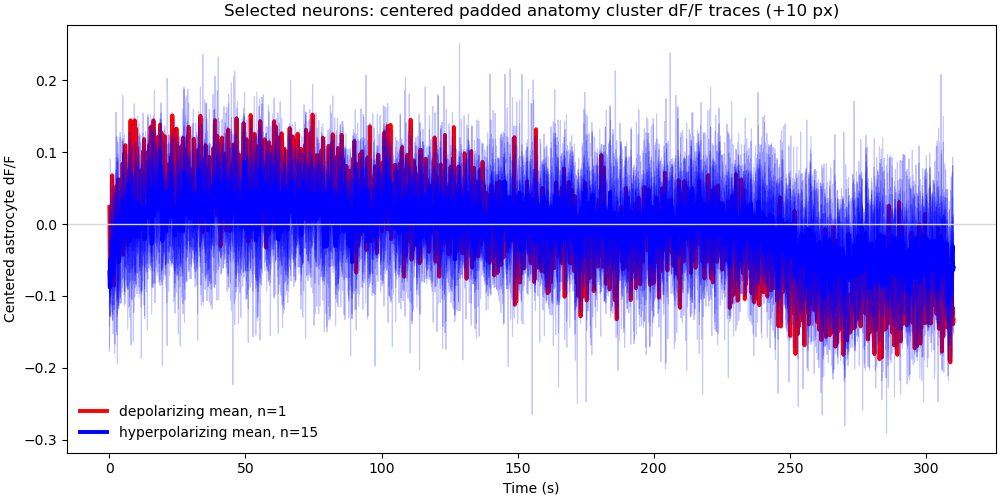

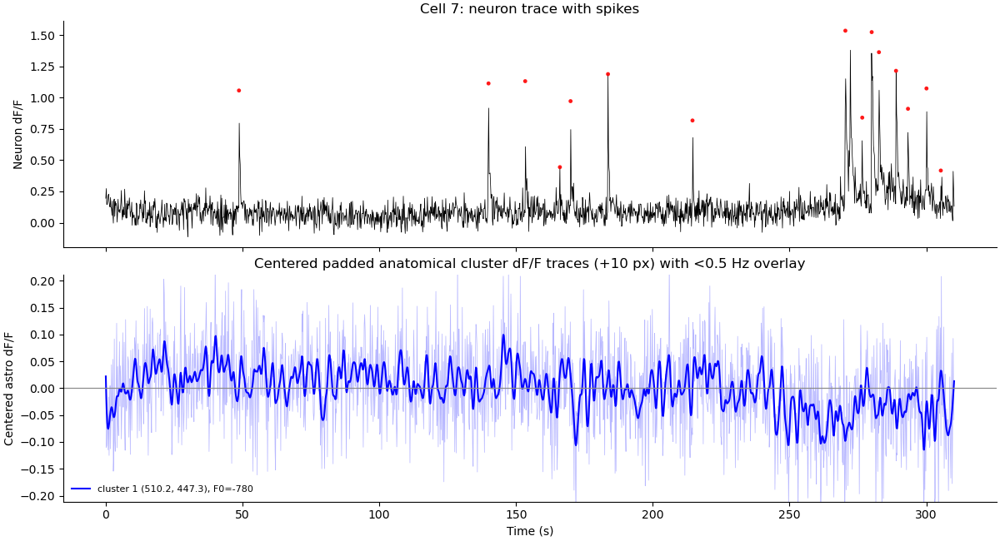

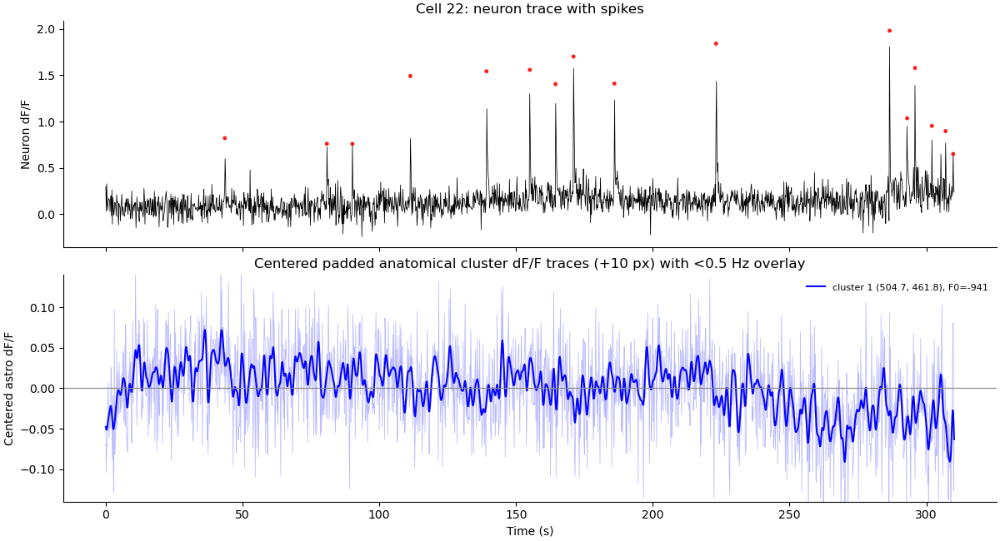

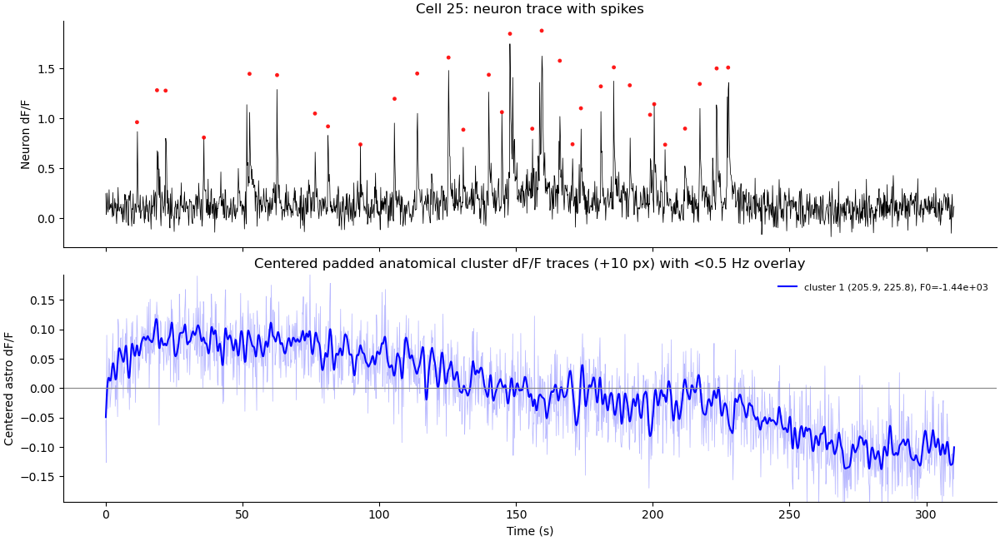

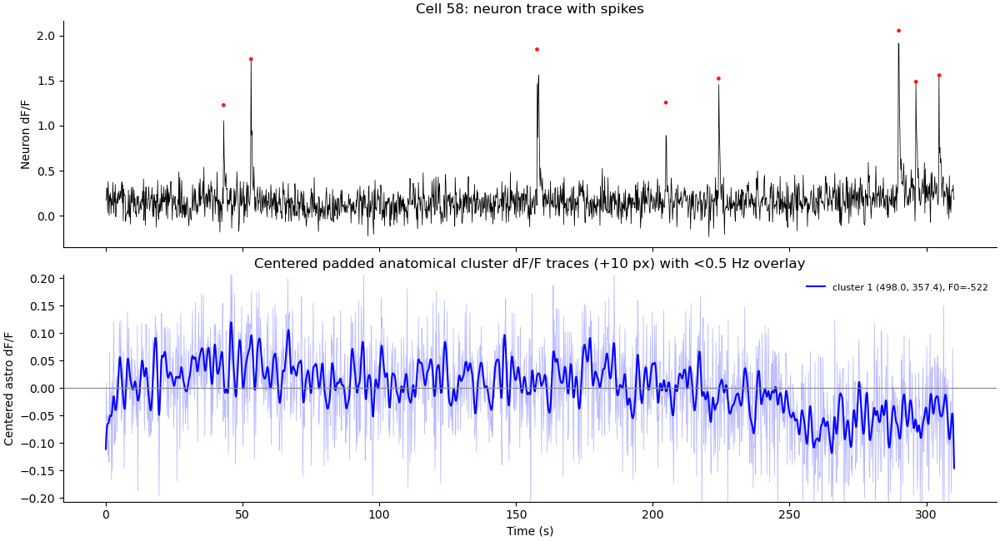

...

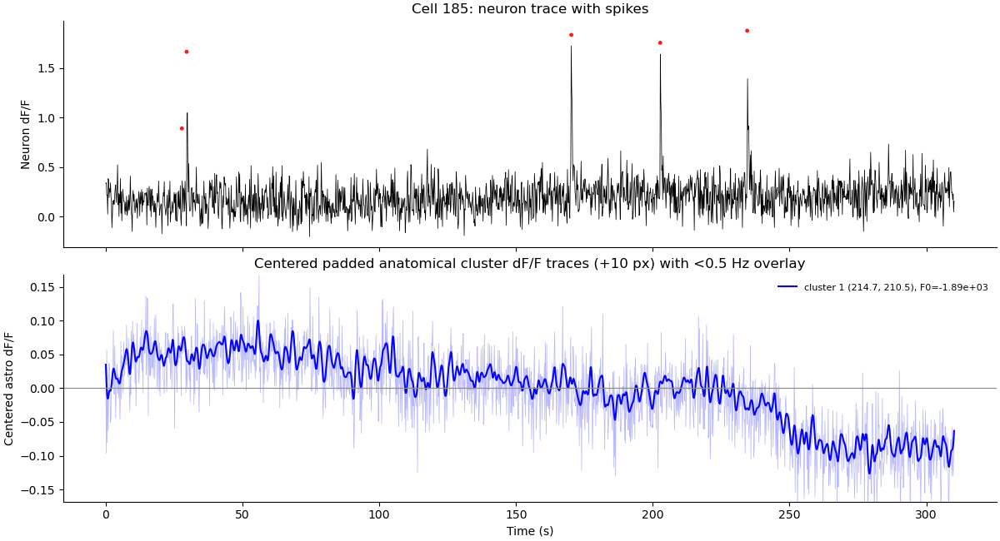

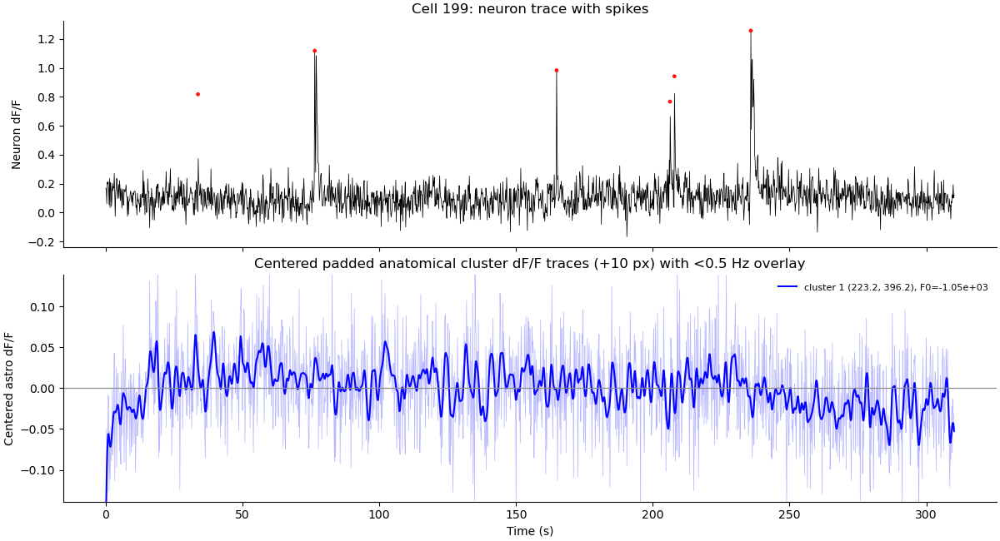

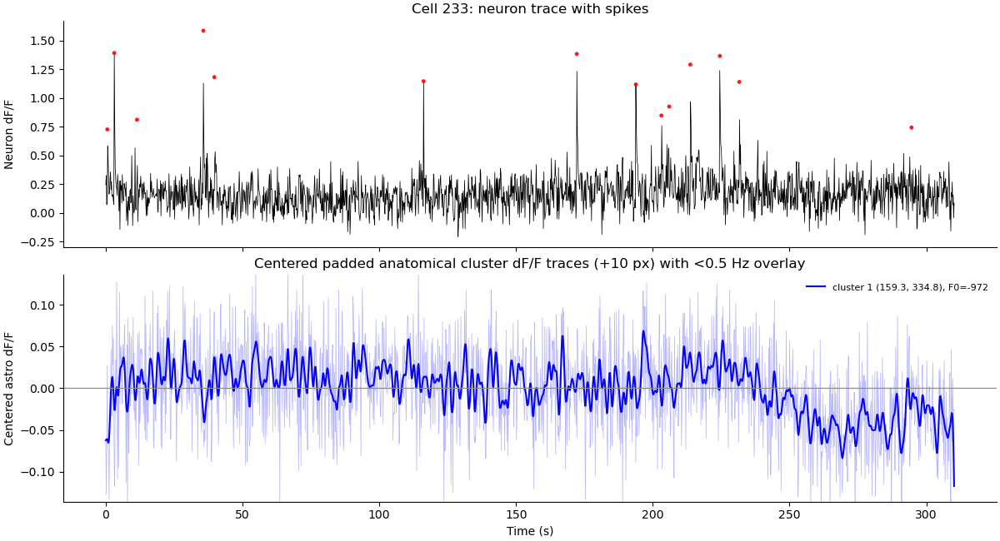

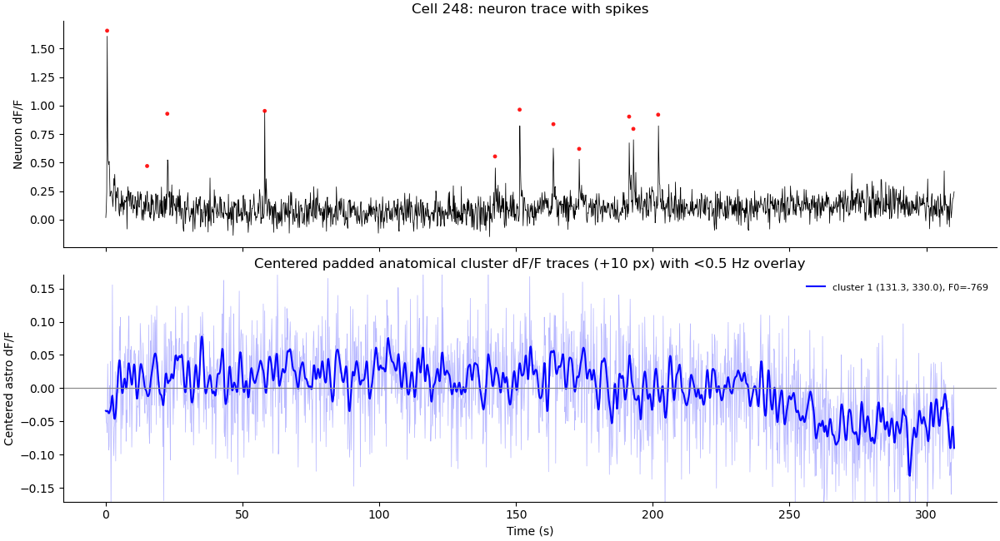

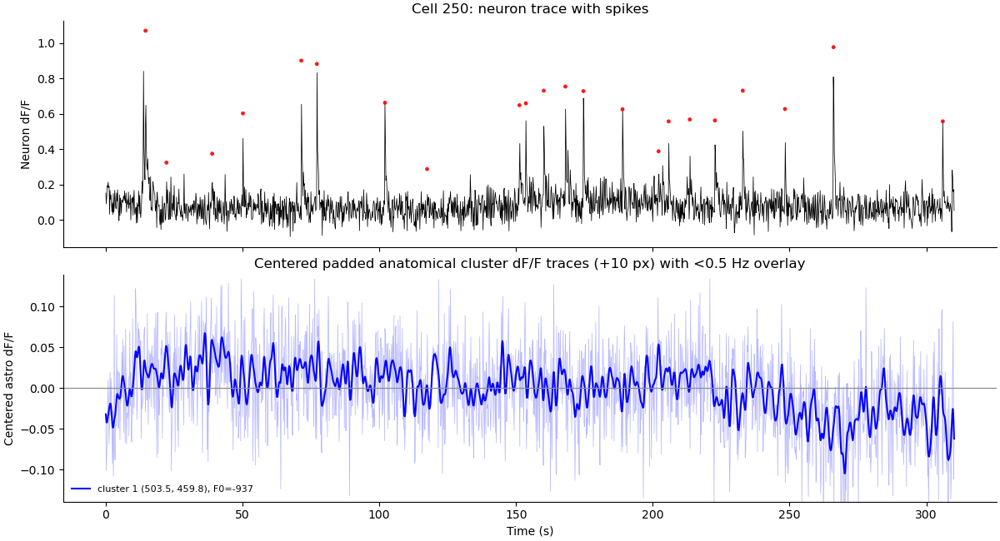

Used padded raw cluster trace cache: \\ems\adam-lab\Adam-Lab-Shared\Code\Miki\astro-analysis-pipeline\notebooks\.cache\Hyp8__R__12-08-2026_ans__FOV1__z-120__x2_Hyp8__R__12-08-2026_ans__FOV1__z-120__x2__cell_all__sta__run_75_anatomy_padded10_raw_cluster_traces_display.npz


In [13]:
PAD_PIXELS = 10
selected_neuron_ids = globals().get("selected_neuron_ids", [7, 22, 25, 58, 70, 92, 95, 114, 162, 171, 183, 185, 199, 233, 248, 250])
cluster_colors = globals().get("cluster_colors", {"positive": "red", "negative": "blue"})
astro_movie = globals().get("astro_movie", tifffile.memmap(paths.astro_movie_path))

trace_len = min(F_cells.shape[1], astro_movie.shape[0])
PADDED_MAX_DISPLAY_FRAMES = 2000
step = max(1, int(np.ceil(trace_len / PADDED_MAX_DISPLAY_FRAMES)))
display_frames = np.arange(0, trace_len, step, dtype=int)
display_time_s = display_frames / fps
display_sample_rate_hz = fps / step
LOWPASS_CUTOFF_HZ = 0.5

padded_cache_dir = NOTEBOOK_DIR / ".cache"
padded_cache_dir.mkdir(exist_ok=True)
padded_cache_path = padded_cache_dir / f"{SINGLE_EXPERIMENT}_{sta_run.name}_anatomy_padded{PAD_PIXELS}_raw_cluster_traces_display.npz"
movie_mtime_ns = int(Path(paths.astro_movie_path).stat().st_mtime_ns)
padded_trace_cache = {}
if padded_cache_path.exists():
    with np.load(padded_cache_path, allow_pickle=True) as cache:
        cached_mtime = int(np.asarray(cache.get("movie_mtime_ns", -1)).item()) if "movie_mtime_ns" in cache else -1
        cached_frames = np.asarray(cache.get("display_frames", []), dtype=int)
        if cached_mtime == movie_mtime_ns and np.array_equal(cached_frames, display_frames):
            padded_trace_cache = {k.replace("trace__", "", 1): np.asarray(cache[k], dtype=np.float32) for k in cache.files if k.startswith("trace__")}
padded_cache_changed = False

def anatomy_rows_for_cell_padded(cell_id):
    rows = [r for r in globals().get("cluster_trace_rows", []) if int(r["cell_id"]) == int(cell_id)]
    if rows:
        return rows
    npz_path = paths.sta_dir / f"cell_{int(cell_id)}" / "astro_sta_cluster_permutation_anatomy.npz"
    if not npz_path.exists():
        return []
    built = []
    for spec in significant_cluster_specs_from_npz(npz_path, cluster_colors):
        mask_full = crop_mask_to_fullres(spec["mask_crop"], spec["crop"], spec["spatial_bin"], image_shape)
        built.append({**spec, "cell_id": int(cell_id), "mask_full": mask_full})
    return built

def padded_cluster_mask(mask, pad=10):
    mask = np.asarray(mask, dtype=bool)
    yy, xx = np.where(mask)
    if yy.size == 0:
        return mask.copy(), (np.nan, np.nan), (-1, -1, -1, -1)
    cy, cx = float(np.mean(yy)), float(np.mean(xx))
    y0 = max(0, int(yy.min()) - int(pad))
    y1 = min(mask.shape[0], int(yy.max()) + int(pad) + 1)
    x0 = max(0, int(xx.min()) - int(pad))
    x1 = min(mask.shape[1], int(xx.max()) + int(pad) + 1)
    padded = np.zeros_like(mask, dtype=bool)
    padded[y0:y1, x0:x1] = True
    return padded, (cy, cx), (y0, y1, x0, x1)

def padded_trace_key(row):
    y0, y1, x0, x1 = row["padded_bounds"]
    return f"cell_{int(row['cell_id'])}_cluster_{int(row.get('component_id', 0))}_{row.get('sign', 'unknown')}_pad{PAD_PIXELS}_{y0}_{y1}_{x0}_{x1}"

def ensure_padded_row(row):
    if "padded_mask_full" not in row:
        padded_mask, centroid, bounds = padded_cluster_mask(row["mask_full"], PAD_PIXELS)
        row = {**row, "padded_mask_full": padded_mask, "cluster_centroid_yx": centroid, "padded_bounds": bounds}
    key = padded_trace_key(row)
    global padded_cache_changed
    if key not in padded_trace_cache:
        padded_trace_cache[key] = cluster_raw_trace_from_movie(astro_movie, row["padded_mask_full"], frame_indices=display_frames)
        padded_cache_changed = True
    raw = np.asarray(padded_trace_cache[key], dtype=float)
    dff, f0 = dff_from_lowest_abs(raw, fraction=0.08)
    center = float(np.nanmedian(dff)) if np.isfinite(dff).any() else 0.0
    dff_centered = dff - center
    low = lowpass_centered(dff_centered, display_sample_rate_hz, cutoff_hz=LOWPASS_CUTOFF_HZ)
    return {**row, "padded_raw_trace": raw, "padded_dff_trace": dff, "padded_dff_centered": dff_centered, "padded_lowpass_trace": low, "padded_f0": f0, "padded_dff_center": center}

padded_cluster_rows = []
for cell_id in selected_neuron_ids:
    for row in anatomy_rows_for_cell_padded(int(cell_id)):
        padded_cluster_rows.append(ensure_padded_row(row))

if padded_cluster_rows:
    fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
    for sign, label in [("positive", "depolarizing"), ("negative", "hyperpolarizing")]:
        rows = [r for r in padded_cluster_rows if r.get("sign") == sign and np.asarray(r.get("padded_dff_centered", [])).size]
        if not rows:
            continue
        arr = np.vstack([np.asarray(r["padded_dff_centered"], dtype=float) for r in rows])
        color = cluster_colors.get(sign, "0.4")
        for y in arr:
            ax.plot(display_time_s, y, color=color, lw=0.8, alpha=0.22)
        ax.plot(display_time_s, np.nanmean(arr, axis=0), color=color, lw=2.8, label=f"{label} mean, n={arr.shape[0]}")
    ax.axhline(0, color="0.85", lw=1)
    ax.set_title(f"Selected neurons: centered padded anatomy cluster dF/F traces (+{PAD_PIXELS} px)")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Centered astrocyte dF/F")
    ax.legend(frameon=False)
    plt.show()
else:
    print("No padded anatomical cluster traces found for selected_neuron_ids.")

for cell_id in selected_neuron_ids:
    cell_id = int(cell_id)
    rows = [r for r in padded_cluster_rows if int(r["cell_id"]) == cell_id]
    if not rows:
        print(f"Cell {cell_id}: no padded anatomical clusters")
        continue
 
    neuron_trace = _suite2p_trace_dff(cell_id, F_raw=F_cells)[:trace_len]
    peaks = spike_peaks.get(cell_id, np.empty(0, dtype=int))
    peaks = peaks[(peaks >= 0) & (peaks < trace_len)]

    fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True, constrained_layout=True)
    ax_n, ax_a = axes
    ax_n.plot(display_time_s, neuron_trace[display_frames], color="black", lw=0.55)
    if peaks.size:
        ax_n.scatter(peaks / fps, neuron_trace[peaks], s=12, color="red", edgecolors="none", alpha=0.9, zorder=4)
    ax_n.set_title(f"Cell {cell_id}: neuron trace with spikes")
    ax_n.set_ylabel("Neuron dF/F")
    ax_n.spines[["top", "right"]].set_visible(False)

    y_values = []
    for i, r in enumerate(rows, start=1):
        y = np.asarray(r["padded_dff_centered"], dtype=float)
        low = np.asarray(r["padded_lowpass_trace"], dtype=float)
        color = cluster_colors.get(r["sign"], "0.4")
        cy, cx = r["cluster_centroid_yx"]
        label = f"cluster {i} ({cy:.1f}, {cx:.1f}), F0={r['padded_f0']:.3g}"
        ax_a.plot(display_time_s, y, color=color, lw=0.55, alpha=0.28)
        ax_a.plot(display_time_s, low, color=color, lw=1.5, alpha=0.98, label=label)
        y_values.extend([y[np.isfinite(y)], low[np.isfinite(low)]])

    ax_a.axhline(0, color="0.55", lw=0.9)
    if y_values:
        vals = np.concatenate([v for v in y_values if v.size])
        lim = max(float(np.nanpercentile(np.abs(vals), 99)), 0.02) * 1.15
        ax_a.set_ylim(-lim, lim)
    ax_a.set_title(f"Centered padded anatomical cluster dF/F traces (+{PAD_PIXELS} px) with <0.5 Hz overlay")
    ax_a.set_xlabel("Time (s)")
    ax_a.set_ylabel("Centered astro dF/F")
    ax_a.legend(frameon=False, fontsize=8, loc="best")
    ax_a.spines[["top", "right"]].set_visible(False)
    plt.show()

if padded_cache_changed:
    np.savez_compressed(
        padded_cache_path,
        movie_mtime_ns=np.asarray(movie_mtime_ns, dtype=np.int64),
        display_frames=display_frames,
        **{f"trace__{k}": np.asarray(v, dtype=np.float32) for k, v in padded_trace_cache.items()},
    )
    print(f"Saved padded raw cluster trace cache: {padded_cache_path}")
else:
    print(f"Used padded raw cluster trace cache: {padded_cache_path}")